# Chapitre 5 - Exercices 5.7 à 5.10

Ce notebook traite les exercices sur la réplication multi-leader, sans leader et la
détection des écritures concurrentes :

- **5.7** : conflits en multi-leader : horloges, identifiants et appareils hors ligne
  (calcul et simulation) ;
- **5.8** : choisir une topologie multi-leader (raisonnement et simulation) ;
- **5.9** : choisir n, w et r (calcul et simulation) ;
- **5.10** : vecteurs de versions à la main (raisonnement et mini-lab).

In [1]:
import itertools
import math
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import replication as rp
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)

## Exercice 5.7 : conflits en multi-leader

**Énoncé.**

1. *Horloges.* Deux leaders résolvent les conflits par LWW avec leurs horloges physiques,
   synchronisées par NTP à ±20 ms près (décalage uniforme dans cet intervalle, indépendant
   pour chaque leader). Un utilisateur modifie son profil sur le leader A puis, 30 ms plus
   tard, le corrige depuis un autre appareil routé vers le leader B. Quelle est la
   probabilité que sa correction soit jetée ?
2. *Identifiants.* Trois leaders attribuent des identifiants auto-incrémentés. Proposer
   un schéma sans collision. Que se passe-t-il si l'on ajoute un quatrième leader ?
3. *Appareils hors ligne.* Un agenda partagé est modifié depuis 3 appareils ; chacun
   reste en moyenne 8 h hors ligne entre deux synchronisations ; un événement donné est
   modifié 2 fois par jour (réparties au hasard entre les appareils). Estimer la
   probabilité qu'une modification soit en conflit.

**Rappels.** LWW et horloges, évitement des conflits par partition de l'espace des
identifiants, conflits $\approx 1 - e^{-\lambda L}$ (cours 3, sections 4 à 6, sections
*Handling Write Conflicts* et *Last write wins*).

**Solution.**

*1.* La correction (horodatage $30 + \varepsilon_B$) perd si $30 + \varepsilon_B <
\varepsilon_A$, soit $\varepsilon_A - \varepsilon_B > 30$ ms. La différence de deux
uniformes sur $[-20, 20]$ suit une loi triangulaire sur $[-40, 40]$ ;
$P(D > 30) = \frac{(40 - 30)^2}{2 \times 40^2} = 3{,}125\,\%$. Une correction sur 32 est
silencieusement annulée.

*2.* Le leader $i \in \{0, 1, 2\}$ attribue $i, i + 3, i + 6, \dots$ (congrus à $i$
modulo 3). Ajouter un quatrième leader casse le schéma : passer au modulo 4 en repartant
de zéro réattribue des identifiants déjà émis (le leader 0 émettrait 4, 8, 12..., déjà
donnés par les leaders 1, 2 et 0 au modulo 3).
Il faut repartir d'un seuil commun (tous les nouveaux identifiants au-delà du maximum
déjà émis), réserver dès le départ un modulo plus grand que nécessaire, ou utiliser des
identifiants (préfixe du leader, compteur) ou des UUID.

*3.* Une modification k n'est vue d'un autre appareil b qu'après la synchronisation de
l'auteur **puis** celle de b ; avec des intervalles exponentiels (sans mémoire), chacune
arrive en moyenne 8 h plus tard : k reste invisible pour b environ 16 h. Une modification
de b est concurrente de k si elle tombe dans les 16 h qui suivent k (b ne connaît pas
encore k) ou dans les 16 h qui précèdent (k ignorait celle de b) : fenêtre d'environ
32 h. Les modifications des **autres** appareils arrivent au rythme
$\lambda \approx 2 \times 2/3 = 1{,}33$ par jour. D'où
$P \approx 1 - e^{-1{,}33 \times 32/24} \approx 83\,\%$ : un ordre de grandeur (les
fenêtres ne sont pas fixes), que la simulation affine. Le message est clair : hors ligne,
une donnée partagée modifiée chaque jour est presque toujours en conflit ; il faut une
fusion automatique.

**Vérification.**

In [2]:
N = 1_000_000
eA, eB = rng.uniform(-20, 20, N), rng.uniform(-20, 20, N)
print(f"1. correction jetée : simulation {100 * np.mean(30 + eB < eA):.2f} %, formule {100 * 10**2 / (2 * 40**2):.3f} %")

def ids(i, k, n, debut=0):
    return {debut + i + k * j for j in range(n)}
anciens = set().union(*(ids(i, 3, 5) for i in range(3)))
nouveaux_naifs = set().union(*(ids(i, 4, 5) for i in range(4)))
nouveaux_seuil = set().union(*(ids(i, 4, 5, debut=max(anciens) + 1) for i in range(4)))
print("2. collisions modulo 4 naïf :", sorted(anciens & nouveaux_naifs), "| avec seuil :", sorted(anciens & nouveaux_seuil))

def agenda(jours=2000, n_app=3, hors_ligne_h=8.0, modifs_par_jour=2.0, seed=1):
    rnd = np.random.default_rng(seed)
    T = jours * 24.0
    syncs = [np.cumsum(rnd.exponential(hors_ligne_h, int(T / hors_ligne_h * 2))) for _ in range(n_app)]
    t_mod = np.sort(rnd.uniform(0, T, rnd.poisson(modifs_par_jour * jours)))
    app = rnd.integers(0, n_app, len(t_mod))
    def prochaine(a, t):
        s = syncs[a]
        return s[np.searchsorted(s, t)]
    def precedente(a, t):
        s = syncs[a]; k = np.searchsorted(s, t) - 1
        return s[k] if k >= 0 else 0.0
    # une modification m est connue de l'appareil b à partir de max(sync de l'auteur après m, puis sync de b après)
    visible = [{b: (prochaine(b, prochaine(app[k], t)) if b != app[k] else t) for b in range(n_app)}
               for k, t in enumerate(t_mod)]
    conflit = np.zeros(len(t_mod), bool)
    for k in range(len(t_mod)):
        for j in range(k + 1, len(t_mod)):
            if t_mod[j] > t_mod[k] + 72:
                break
            if app[j] != app[k] and visible[k][app[j]] > t_mod[j]:
                conflit[k] = conflit[j] = True            # j ignorait k : écritures concurrentes
    return conflit.mean()

print(f"3. modifications en conflit (simulation) : {100 * agenda():.0f} %  ; estimation : {100 * (1 - math.exp(-4 / 3 * 32 / 24)):.0f} %")

1. correction jetée : simulation 3.13 %, formule 3.125 %
2. collisions modulo 4 naïf : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14] | avec seuil : []
3. modifications en conflit (simulation) : 78 %  ; estimation : 83 %


La simulation de l'agenda tient compte du fait que l'auteur et le lecteur doivent tous
deux se synchroniser ; elle confirme l'ordre de grandeur : plus de trois modifications
sur quatre sont concurrentes d'une autre.

> **À retenir.** Avec des horloges physiques, LWW jette aussi des écritures successives ;
> partitionner l'espace des identifiants évite les collisions tant que le nombre de
> leaders ne change pas ; hors ligne, les conflits sont la règle et non l'exception.

## Exercice 5.8 : choisir une topologie multi-leader

**Énoncé.** Cinq centres de données ont chacun un leader. Le délai d'un message entre deux
sites est de 50 ms en moyenne (exponentiel) ; chaque leader est indisponible 0,5 % du
temps.

1. Pour les topologies circulaire, en étoile (racine fixe) et tout-à-tout, donner le
   nombre de messages par écriture, le nombre maximal de sauts et le délai moyen de
   propagation jusqu'au site le plus éloigné.
2. Quelle est la probabilité qu'à un instant donné toutes les écritures de tous les
   leaders disponibles atteignent tous les autres leaders disponibles ?
3. Une application insère une ligne puis la modifie 100 ms plus tard sur un autre leader.
   Dans quelle(s) topologie(s) la modification peut-elle dépasser l'insertion ?
   Vérifier par simulation en faisant varier ce délai.

**Rappels.** Topologies, transmission avec identifiants de nœuds traversés, messages qui
se doublent (cours 3, section 3, section *Multi-leader replication topologies*).

**Solution.**

*1.* Dans les trois cas, chaque autre leader reçoit l'écriture exactement une fois :
$n - 1 = 4$ messages par écriture. Sauts maximaux : circulaire 4, étoile 2 (feuille ->
racine -> feuille), tout-à-tout 1. Délai jusqu'au dernier site : circulaire, somme de 4
délais, soit 200 ms en moyenne ; étoile, depuis une feuille, un délai vers la racine puis
le maximum de 3 délais, $50 + 50 \times (1 + \tfrac12 + \tfrac13) \approx 142$ ms ;
tout-à-tout, le maximum de 4 délais indépendants,
$50 \times (1 + \tfrac12 + \tfrac13 + \tfrac14) \approx 104$ ms.

*2.* Circulaire : il faut les 5 nœuds disponibles (sinon l'anneau est coupé),
$0{,}995^5 \approx 97{,}5\,\%$. Étoile : il suffit que la racine soit disponible (une
feuille en panne ne gêne que ses propres échanges), $99{,}5\,\%$. Tout-à-tout : toujours
(100 %, aux liens près).

*3.* Avec des liens FIFO, ni l'anneau ni l'étoile ne permettent le dépassement : la
modification emprunte, à partir du nœud qui a vu l'insertion, le même chemin qu'elle. En
tout-à-tout, le leader C reçoit l'insertion directement de A et la modification
directement de B ; si le délai A -> C dépasse la somme des délais A -> B, du temps de
réflexion et du délai B -> C, la modification arrive d'abord.

,sauts max,délai jusqu'au dernier (ms),tout est relayé (%)
topologie,,,
circulaire,4,199.8,97.5
étoile,2,141.5,99.5
tout-à-tout,1,104.1,100.0


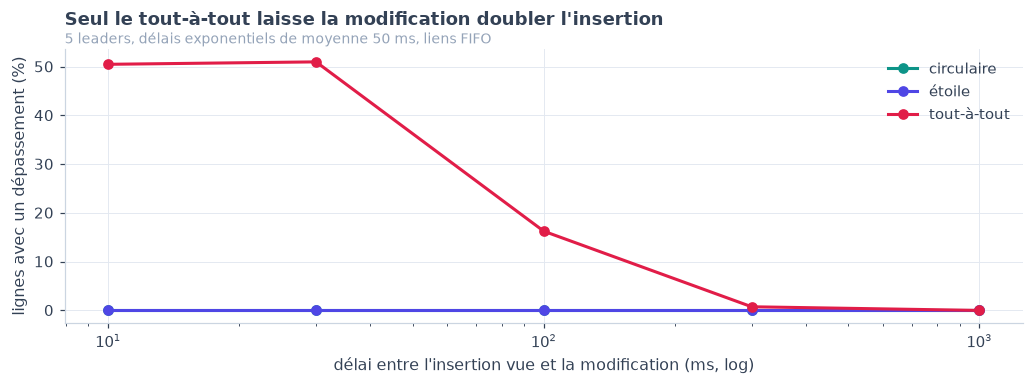

In [3]:
rows = []
for kind, lab in [("circulaire", "circulaire"), ("etoile", "étoile"), ("tout", "tout-à-tout")]:
    topo = rp.topology(kind, [f"L{i}" for i in range(1, 6)])
    hops = max(max(rp.propagate(topo, o).values()) for o in topo)
    rows.append({"topologie": lab, "sauts max": hops})
delais = rng.exponential(50, (200000, 4))
rows[0]["délai jusqu'au dernier (ms)"] = delais.sum(axis=1).mean()
rows[1]["délai jusqu'au dernier (ms)"] = (delais[:, 0] + delais[:, 1:].max(axis=1)).mean()
rows[2]["délai jusqu'au dernier (ms)"] = delais.max(axis=1).mean()
for r_, p in zip(rows, [0.995 ** 5, 0.995, 1.0]):
    r_["tout est relayé (%)"] = 100 * p
display(pd.DataFrame(rows).set_index("topologie").round(1))

def lat_exp(rng_, s, d):
    return rng_.expovariate(1 / 0.05)
gaps = [0.01, 0.03, 0.1, 0.3, 1.0]
res = {k: [] for k in ("circulaire", "etoile", "tout")}
for g in gaps:
    for k in res:
        r_ = rp.run_topology(k, n_nodes=5, n_rows=400, gap=g, latency=lat_exp, seed=2)
        res[k].append(100 * r_["violations"] / 400)
fig, ax = plt.subplots(figsize=(9.5, 3.6))
for (k, v), c in zip(res.items(), [TEAL, INDIGO, ROSE]):
    ax.plot(np.array(gaps) * 1000, v, "o-", color=c, label={"circulaire": "circulaire", "etoile": "étoile", "tout": "tout-à-tout"}[k])
ax.set_xscale("log"); ax.set_xlabel("délai entre l'insertion vue et la modification (ms, log)")
ax.set_ylabel("lignes avec un dépassement (%)")
ax.set_title("Seul le tout-à-tout laisse la modification doubler l'insertion")
subtitle(ax, "5 leaders, délais exponentiels de moyenne 50 ms, liens FIFO")
ax.legend()
plt.tight_layout(); plt.show()

Les délais simulés confirment le calcul (200, 142 et 104 ms). Le dépassement est
fréquent en tout-à-tout tant que le délai entre insertion et modification est comparable
au délai réseau, et disparaît quand il le dépasse largement ; il est nul ailleurs. Le
tout-à-tout reste en général le bon choix (tolérance aux pannes, faible latence), à
condition de **suivre la causalité** (vecteurs de versions, ou au minimum mise en attente
des mises à jour orphelines).

> **À retenir.** Toutes les topologies coûtent n - 1 messages par écriture ; elles
> diffèrent par la latence, la fragilité face aux pannes et l'ordre de livraison.